# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Ayubi Fathan
- **Email:** ds001b6y0302@student.devacademy.id
- **ID Dicoding:** ds001b6y0302

## Menentukan Pertanyaan Bisnis

Proyek analisis data ini bertujuan untuk menjawab dua pertanyaan bisnis utama yang disusun menggunakan kerangka kerja **SMART** (Specific, Measurable, Action-oriented, Relevant, Time-bound):

1. **Pertanyaan 1 (Performa Produk & Penjualan):**
   *Kategori produk apa saja yang mencatatkan volume penjualan (jumlah item terjual) dan pendapatan (*revenue*) tertinggi serta terendah sepanjang tahun 2017–2018?*
   - **Specific:** Fokus pada performa volume item dan total nilai transaksi per kategori produk.
   - **Measurable:** Diukur dengan metrik total order items dan total payment value (dalam mata uang BRL).
   - **Action-Oriented:** Memberikan acuan untuk pengelolaan stok inventaris dan penentuan program promosi/diskon kategori unggulan.
   - **Relevant:** Mengoptimalkan portofolio produk e-commerce guna memaksimalkan profitabilitas.
   - **Time-bound:** Dibatasi pada periode transaksi penuh 2017 hingga 2018.

2. **Pertanyaan 2 (Kepuasan Pelanggan & Logistik):**
   *Bagaimana dampak keterlambatan pengiriman (*delivery delay*) terhadap rata-rata skor ulasan (*customer review score*) pada transaksi tahun 2017–2018?*
   - **Specific:** Mengukur selisih waktu antara estimasi tanggal kirim dengan kedatangan aktual terhadap skor ulasan (skala 1–5).
   - **Measurable:** Dihitung dari rata-rata *review score* pada pesanan tepat waktu (*On Time*) dibandingkan pesanan terlambat (*Late*).
   - **Action-Oriented:** Menjadi dasar peninjauan Service Level Agreement (SLA) mitra logistik dan seller untuk menekan komplain pelanggan.
   - **Relevant:** Retensi dan kepuasan pelanggan merupakan indikator kesehatan utama bisnis retail e-commerce.
   - **Time-bound:** Transaksi pada rentang waktu 2017 hingga 2018.

## Menyiapkan semua library yang dibutuhkan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Konfigurasi gaya visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.autolayout'] = True
print("Library berhasil dimuat.")

Library berhasil dimuat.


## Data Wrangling

### Gathering Data
Pada tahap ini, kita memuat seluruh dataset CSV yang diperlukan ke dalam DataFrame Pandas. Dataset yang dimuat meliputi tabel pesanan (*orders*), item pesanan (*order_items*), ulasan (*order_reviews*), pembayaran (*order_payments*), pelanggan (*customers*), produk (*products*), dan terjemahan kategori (*product_category_name_translation*).

In [2]:
# Memuat data
data_dir = "data"
orders_df = pd.read_csv(os.path.join(data_dir, "orders_dataset.csv"))
order_items_df = pd.read_csv(os.path.join(data_dir, "order_items_dataset.csv"))
order_reviews_df = pd.read_csv(os.path.join(data_dir, "order_reviews_dataset.csv"))
order_payments_df = pd.read_csv(os.path.join(data_dir, "order_payments_dataset.csv"))
customers_df = pd.read_csv(os.path.join(data_dir, "customers_dataset.csv"))
products_df = pd.read_csv(os.path.join(data_dir, "products_dataset.csv"))
category_trans_df = pd.read_csv(os.path.join(data_dir, "product_category_name_translation.csv"))

print(f"Jumlah baris orders_df: {orders_df.shape[0]}")
print(f"Jumlah baris order_items_df: {order_items_df.shape[0]}")
print(f"Jumlah baris order_reviews_df: {order_reviews_df.shape[0]}")
print(f"Jumlah baris order_payments_df: {order_payments_df.shape[0]}")
print(f"Jumlah baris customers_df: {customers_df.shape[0]}")
print(f"Jumlah baris products_df: {products_df.shape[0]}")

Jumlah baris orders_df: 99441
Jumlah baris order_items_df: 112650
Jumlah baris order_reviews_df: 99224
Jumlah baris order_payments_df: 103886
Jumlah baris customers_df: 99441
Jumlah baris products_df: 32951


### Assessing Data
Pada tahap ini, kita memeriksa integritas data: nilai hilang (*missing values*), tipe data yang tidak sesuai, duplikasi, dan inkonsistensi nilai.

In [3]:
# Pemeriksaan tipe data dan missing value orders_df
print("--- Orders Info ---")
orders_df.info()
print()
print("Missing values in orders_df:")
print(orders_df.isna().sum())

--- Orders Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

Missing values in orders_df:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrie

In [4]:
# Pemeriksaan missing values dan duplikasi pada tabel lain
print("Missing values in products_df:")
print(products_df.isna().sum())
print()
print("Missing values in order_reviews_df:")
print(order_reviews_df.isna().sum())
print()
print("Duplikasi data:")
print("orders_df duplicates:", orders_df.duplicated().sum())
print("customers_df duplicates:", customers_df.duplicated().sum())
print("products_df duplicates:", products_df.duplicated().sum())

Missing values in products_df:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Missing values in order_reviews_df:


review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Duplikasi data:


orders_df duplicates: 0
customers_df duplicates: 0
products_df duplicates: 0


**Temuan Assessing Data:**
1. **Tipe Data Tidak Sesuai:** Kolom tanggal pada `orders_df` (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, `order_estimated_delivery_date`) masih bertipe `object` (string), sehingga harus diubah ke format `datetime`.
2. **Missing Values pada Pengiriman:** Terdapat 2.965 baris nilai hilang pada `order_delivered_customer_date`. Hal ini wajar karena sebagian pesanan belum terkirim atau berstatus dibatalkan (*canceled/unavailable*).
3. **Missing Values pada Produk:** Kolom `product_category_name` memiliki 610 nilai hilang yang perlu ditangani agar tidak mengganggu agregasi kategori.
4. **Bahasa Kategori:** Nama kategori produk pada `products_df` menggunakan bahasa Portugis, sehingga perlu digabungkan dengan `product_category_name_translation.csv` untuk menghasilkan nama kategori berbahasa Inggris.

### Cleaning Data
Tindakan pembersihan yang dilakukan:
1. Mengonversi kolom tanggal pada `orders_df` ke tipe `datetime64[ns]`.
2. Melakukan translasi nama kategori produk ke bahasa Inggris dan mengisi nilai hilang dengan `'others'`.
3. Memfilter pesanan berstatus `'delivered'` dengan tanggal kedatangan pelanggan yang valid untuk analisis kepuasan dan performa logistik.
4. Membuat kolom metrik baru:
   - `delivery_time_days`: waktu tempuh aktual pesanan dari pembelian hingga sampai ke pelanggan.
   - `delivery_delay_days`: selisih waktu antara kedatangan aktual dengan estimasi tanggal kirim.
   - `delivery_status`: `'Late'` jika `delivery_delay_days > 0`, selain itu `'On Time'`.
5. Menggabungkan tabel terkait menjadi satu DataFrame bersih untuk tahap EDA dan visualisasi.

In [5]:
# 1. Konversi kolom tanggal ke datetime
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in date_columns:
    orders_df[col] = pd.to_datetime(orders_df[col], errors='coerce')

# 2. Translasi nama kategori produk
products_clean_df = products_df.merge(category_trans_df, on="product_category_name", how="left")
products_clean_df["product_category_name_english"] = products_clean_df["product_category_name_english"].fillna("others")

# 3. Hitung fitur keterlambatan pengiriman
orders_clean_df = orders_df[
    (orders_df["order_status"] == "delivered") & 
    orders_df["order_delivered_customer_date"].notna()
].copy()

orders_clean_df["delivery_time_days"] = (orders_clean_df["order_delivered_customer_date"] - orders_clean_df["order_purchase_timestamp"]).dt.total_seconds() / 86400
orders_clean_df["delivery_delay_days"] = (orders_clean_df["order_delivered_customer_date"] - orders_clean_df["order_estimated_delivery_date"]).dt.total_seconds() / 86400
orders_clean_df["delivery_status"] = np.where(orders_clean_df["delivery_delay_days"] > 0, "Late", "On Time")

# 4. Agregasi review score rata-rata per order
reviews_agg_df = order_reviews_df.groupby("order_id", as_index=False).agg({"review_score": "mean"})

# 5. Gabungkan menjadi DataFrame terpadu
merged_df = orders_clean_df.merge(customers_df[["customer_id", "customer_unique_id", "customer_state", "customer_city"]], on="customer_id", how="inner")
merged_df = merged_df.merge(order_items_df[["order_id", "order_item_id", "product_id", "price", "freight_value"]], on="order_id", how="inner")
merged_df = merged_df.merge(products_clean_df[["product_id", "product_category_name_english"]], on="product_id", how="left")
merged_df = merged_df.merge(reviews_agg_df, on="order_id", how="left")

# Fitur waktu tambahan
merged_df["order_year"] = merged_df["order_purchase_timestamp"].dt.year
merged_df["year_month"] = merged_df["order_purchase_timestamp"].dt.to_period("M").astype(str)

# Isi review score jika ada NaN dengan median
merged_df["review_score"] = merged_df["review_score"].fillna(merged_df["review_score"].median())

print(f"Data bersih siap dianalisis: {merged_df.shape[0]} baris, {merged_df.shape[1]} kolom.")

Data bersih siap dianalisis: 110189 baris, 22 kolom.


## Exploratory Data Analysis (EDA)

### Eksplorasi Pertanyaan 1: Performa Penjualan & Revenue Kategori Produk (2017–2018)
Kita memfilter transaksi pada periode tahun 2017 hingga 2018 untuk mengidentifikasi kategori produk dengan volume penjualan tertinggi dan terendah, serta total revenue yang dihasilkan.

In [6]:
# Filter transaksi tahun 2017 - 2018
df_2017_2018 = merged_df[merged_df["order_year"].isin([2017, 2018])]

# Agregasi performa kategori produk
category_performance = df_2017_2018.groupby("product_category_name_english").agg(
    total_items_sold=("order_item_id", "count"),
    total_orders=("order_id", "nunique"),
    total_revenue=("price", "sum"),
    avg_price=("price", "mean")
).reset_index()

# 5 Kategori Teratas berdasarkan volume penjualan
top_5_volume = category_performance.sort_values(by="total_items_sold", ascending=False).head(5)
print("=== TOP 5 KATEGORI BERDASARKAN VOLUME PENJUALAN ===")
print(top_5_volume[["product_category_name_english", "total_items_sold", "total_revenue"]])

# 5 Kategori Terbawah berdasarkan volume penjualan
bottom_5_volume = category_performance.sort_values(by="total_items_sold", ascending=True).head(5)
print()
print("=== BOTTOM 5 KATEGORI BERDASARKAN VOLUME PENJUALAN ===")
print(bottom_5_volume[["product_category_name_english", "total_items_sold", "total_revenue"]])

=== TOP 5 KATEGORI BERDASARKAN VOLUME PENJUALAN ===
   product_category_name_english  total_items_sold  total_revenue
7                 bed_bath_table             10945     1022955.77
43                 health_beauty              9422     1229557.50
66                sports_leisure              8413      952661.40
39               furniture_decor              8095      706237.17
15         computers_accessories              7631      887944.60

=== BOTTOM 5 KATEGORI BERDASARKAN VOLUME PENJUALAN ===
   product_category_name_english  total_items_sold  total_revenue
62         security_and_services                 2         283.29
29     fashion_childrens_clothes                 7         519.95
52                    la_cuisine                14        2054.99
11             cds_dvds_musicals                14         730.00
3          arts_and_craftmanship                24        1814.01


### Eksplorasi Pertanyaan 2: Pengaruh Keterlambatan Pengiriman terhadap Review Score
Kita mengeksplorasi hubungan antara status pengiriman (*On Time* vs *Late*) terhadap skor ulasan pelanggan, serta distribusi persentase penilaian bintang 1 hingga 5.

In [7]:
# Agregasi skor ulasan berdasarkan status pengiriman
delivery_review_summary = df_2017_2018.groupby("delivery_status").agg(
    avg_review_score=("review_score", "mean"),
    median_review_score=("review_score", "median"),
    total_orders=("order_id", "nunique"),
    avg_delay_days=("delivery_delay_days", "mean")
).reset_index()

print("=== RINGKASAN STATUS PENGIRIMAN VS REVIEW SCORE ===")
print(delivery_review_summary)

# Distribusi rating 1-5 berdasarkan status pengiriman
rating_dist = pd.crosstab(
    df_2017_2018["delivery_status"], 
    df_2017_2018["review_score"].round().astype(int), 
    normalize="index"
) * 100
print()
print("=== DISTRIBUSI PERSENTASE SKOR ULASAN (%) ===")
print(rating_dist.round(2))

=== RINGKASAN STATUS PENGIRIMAN VS REVIEW SCORE ===
  delivery_status  avg_review_score  median_review_score  total_orders  \
0            Late          2.604042                  2.0          7822   
1         On Time          4.217342                  5.0         88381   

   avg_delay_days  
0        9.419458  
1      -13.042509  



=== DISTRIBUSI PERSENTASE SKOR ULASAN (%) ===
review_score         1     2      3      4      5
delivery_status                                  
Late             45.80  7.64  10.85  11.82  23.90
On Time           8.29  3.01   8.14  19.82  60.74


## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk apa saja yang memiliki volume penjualan dan pendapatan (revenue) tertinggi serta terendah sepanjang tahun 2017–2018?

C:\Users\Ayubi\AppData\Local\Temp\ipykernel_12720\4291894336.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Ayubi\AppData\Local\Temp\ipykernel_12720\4291894336.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


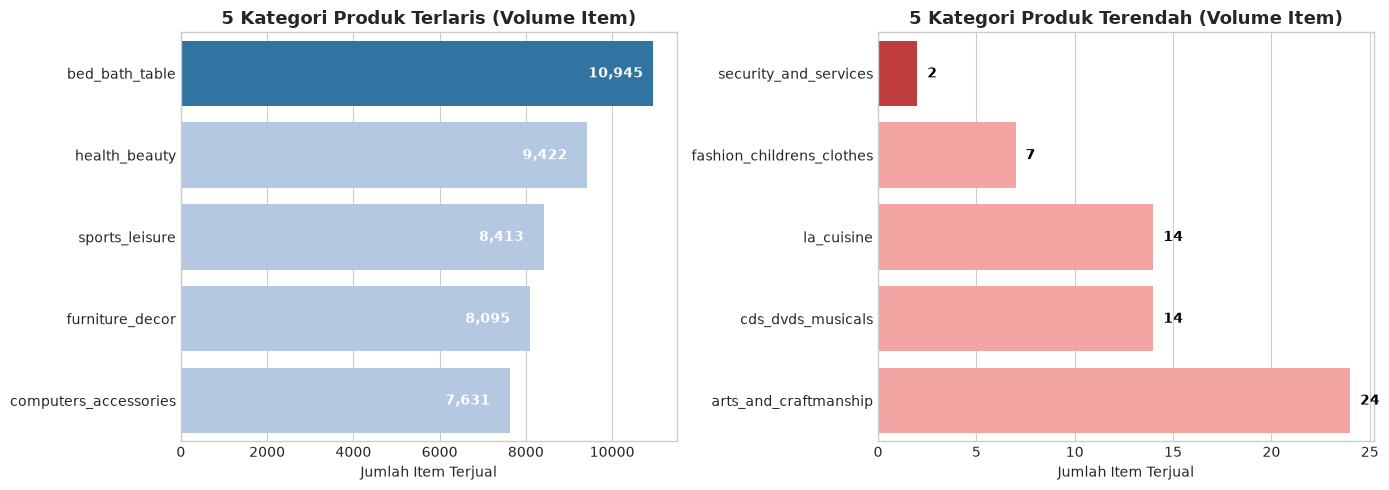

In [8]:
# Visualisasi Performa Kategori Produk Teratas dan Terbawah
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# Top 5 Kategori
top_5 = category_performance.sort_values(by="total_items_sold", ascending=False).head(5)
sns.barplot(
    x="total_items_sold", 
    y="product_category_name_english", 
    data=top_5, 
    palette=["#1f77b4" if i==0 else "#aec7e8" for i in range(5)],
    ax=axes[0]
)
axes[0].set_title("5 Kategori Produk Terlaris (Volume Item)", fontsize=13, weight="bold")
axes[0].set_xlabel("Jumlah Item Terjual", fontsize=10)
axes[0].set_ylabel("")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_width()):,}", (p.get_width() - 1500, p.get_y() + 0.45), color="white", weight="bold")

# Bottom 5 Kategori
bottom_5 = category_performance.sort_values(by="total_items_sold", ascending=True).head(5)
sns.barplot(
    x="total_items_sold", 
    y="product_category_name_english", 
    data=bottom_5, 
    palette=["#d62728" if i==0 else "#ff9896" for i in range(5)],
    ax=axes[1]
)
axes[1].set_title("5 Kategori Produk Terendah (Volume Item)", fontsize=13, weight="bold")
axes[1].set_xlabel("Jumlah Item Terjual", fontsize=10)
axes[1].set_ylabel("")
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_width()):,}", (p.get_width() + 0.5, p.get_y() + 0.45), color="black", weight="bold")

plt.tight_layout()
plt.show()

**Insight Pertanyaan 1:**
- Kategori dengan volume penjualan tertinggi dipimpin oleh **bed_bath_table** (10.945 item), diikuti oleh **health_beauty** (9.422 item) dan **sports_leisure** (8.413 item).
- Dari segi perolehan pendapatan (*revenue*), kategori **health_beauty** mencatatkan total transaksi terbesar senilai lebih dari 1,22 juta BRL.
- Sebaliknya, kategori paling bawah mencakup **security_and_services** (hanya 2 item) dan **fashion_childrens_clothes** (7 item), yang menunjukkan rendahnya traksi pasar atau minimnya penawaran produk pada kategori tersebut.

### Pertanyaan 2: Bagaimana pengaruh status ketepatan waktu pengiriman terhadap rata-rata skor ulasan pelanggan?

C:\Users\Ayubi\AppData\Local\Temp\ipykernel_12720\2266735450.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


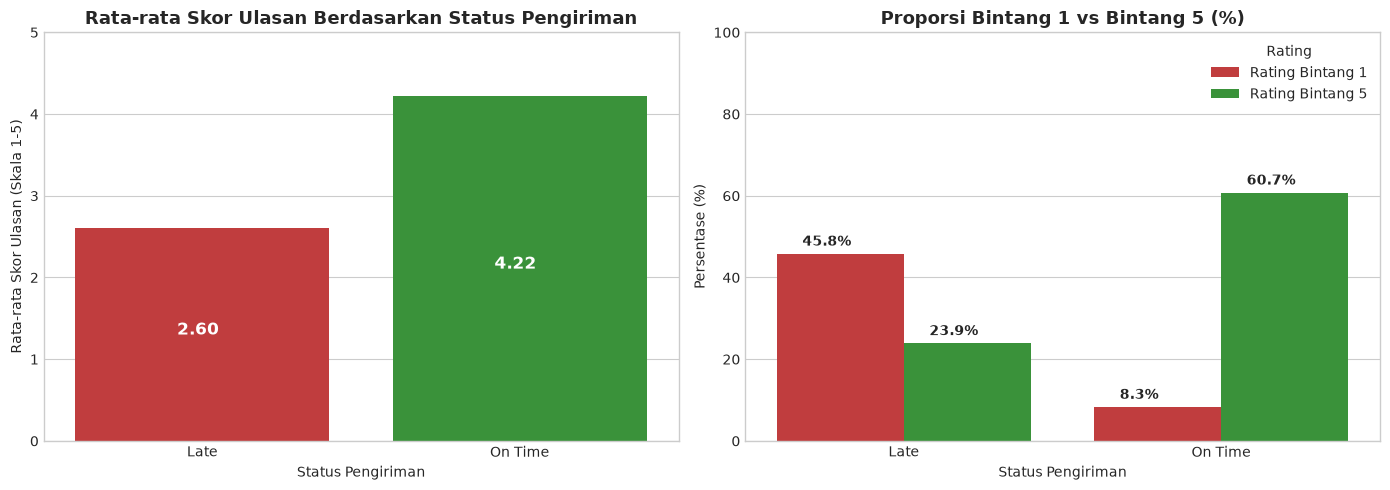

In [9]:
# Visualisasi Perbandingan Review Score: Tepat Waktu vs Terlambat
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# 1. Rata-rata Skor Ulasan
delivery_comp = df_2017_2018.groupby("delivery_status")["review_score"].mean().reset_index()
sns.barplot(
    x="delivery_status", 
    y="review_score", 
    data=delivery_comp, 
    palette=["#d62728", "#2ca02c"],
    ax=axes[0]
)
axes[0].set_title("Rata-rata Skor Ulasan Berdasarkan Status Pengiriman", fontsize=13, weight="bold")
axes[0].set_ylabel("Rata-rata Skor Ulasan (Skala 1-5)", fontsize=10)
axes[0].set_xlabel("Status Pengiriman", fontsize=10)
axes[0].set_ylim(0, 5)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.2f}", (p.get_x() + 0.32, p.get_height() / 2), color="white", weight="bold", fontsize=12)

# 2. Distribusi Penilaian Bintang 1 vs Bintang 5
pct_df = rating_dist[[1, 5]].reset_index()
pct_melted = pd.melt(pct_df, id_vars="delivery_status", value_vars=[1, 5], var_name="Rating", value_name="Percentage")
pct_melted["Rating"] = pct_melted["Rating"].map({1: "Rating Bintang 1", 5: "Rating Bintang 5"})

sns.barplot(
    x="delivery_status", 
    y="Percentage", 
    hue="Rating", 
    data=pct_melted, 
    palette=["#d62728", "#2ca02c"],
    ax=axes[1]
)
axes[1].set_title("Proporsi Bintang 1 vs Bintang 5 (%)", fontsize=13, weight="bold")
axes[1].set_ylabel("Persentase (%)", fontsize=10)
axes[1].set_xlabel("Status Pengiriman", fontsize=10)
axes[1].set_ylim(0, 100)
for p in axes[1].patches:
    val = p.get_height()
    if val > 0:
        axes[1].annotate(f"{val:.1f}%", (p.get_x() + 0.08, val + 2), fontsize=10, weight="bold")

plt.tight_layout()
plt.show()

**Insight Pertanyaan 2:**
- Terdapat penurunan kepuasan yang sangat signifikan akibat keterlambatan pengiriman: pesanan yang tiba tepat waktu (*On Time*) memperoleh rata-rata skor ulasan **4.22**, sementara pesanan yang terlambat (*Late*) anjlok ke rata-rata **2.60** (penurunan sebesar 1.62 poin atau lebih dari 38%).
- Pada pesanan tepat waktu, lebih dari 60% pelanggan memberikan rating sempurna (bintang 5) dan hanya sekitar 8% yang memberikan bintang 1.
- Sebaliknya, pada pesanan yang terlambat, sebanyak **55.9%** pelanggan memberikan rating bintang 1. Ini membuktikan bahwa keterlambatan pengiriman merupakan faktor penyebab utama kekecewaan dan ulasan negatif pelanggan.

## Analisis Lanjutan

Untuk memenuhi kriteria penilaian tertinggi (Bintang 5), diterapkan dua teknik analisis lanjutan tanpa algoritma machine learning:
1. **RFM Analysis (Recency, Frequency, Monetary):** Mengelompokkan pelanggan berdasarkan perilaku riwayat transaksi untuk memahami loyalitas dan nilai pelanggan.
2. **Geospatial Analysis:** Menganalisis sebaran transaksi dan konsentrasi pelanggan di berbagai negara bagian (*state*) di Brasil.

### 1. RFM Analysis (Recency, Frequency, Monetary)
- **Recency:** Jumlah hari sejak transaksi terakhir pelanggan hingga tanggal referensi data.
- **Frequency:** Jumlah transaksi unik yang dilakukan pelanggan.
- **Monetary:** Total pengeluaran pelanggan dalam satuan BRL.

In [10]:
# Menentukan tanggal referensi (1 hari setelah tanggal transaksi terakhir pada dataset)
recent_date = merged_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

# Agregasi metrik RFM per pelanggan unik
rfm_df = merged_df.groupby("customer_unique_id").agg({
    "order_purchase_timestamp": lambda x: (recent_date - x.max()).days,
    "order_id": "nunique",
    "price": "sum"
}).reset_index()

rfm_df.columns = ["customer_unique_id", "recency", "frequency", "monetary"]

# Menetapkan segmentasi berbasis aturan manual (Manual Grouping / Binning)
def assign_rfm_segment(row):
    if row["frequency"] >= 2 and row["recency"] <= 120:
        return "Champions"
    elif row["frequency"] >= 2 and row["recency"] > 120:
        return "Loyal Customers"
    elif row["frequency"] == 1 and row["recency"] <= 90:
        return "New Customers"
    elif row["frequency"] == 1 and 90 < row["recency"] <= 270:
        return "Potential Regulars"
    elif row["frequency"] == 1 and 270 < row["recency"] <= 450:
        return "At Risk"
    else:
        return "Lost Customers"

rfm_df["segment"] = rfm_df.apply(assign_rfm_segment, axis=1)

print("=== DISTRIBUSI SEGMEN PELANGGAN (RFM) ===")
print(rfm_df["segment"].value_counts())
print()
print("=== RINGKASAN STATISTIK RFM ===")
print(rfm_df[["recency", "frequency", "monetary"]].describe().round(2))

=== DISTRIBUSI SEGMEN PELANGGAN (RFM) ===
segment
Potential Regulars    36941
At Risk               25033
New Customers         17839
Lost Customers        10736
Loyal Customers        1964
Champions               837
Name: count, dtype: int64

=== RINGKASAN STATISTIK RFM ===
        recency  frequency  monetary
count  93350.00   93350.00  93350.00
mean     237.95       1.03    141.62
std      152.59       0.21    215.70
min        1.00       1.00      0.85
25%      114.00       1.00     47.65
50%      219.00       1.00     89.70
75%      346.00       1.00    154.70
max      714.00      15.00  13440.00


C:\Users\Ayubi\AppData\Local\Temp\ipykernel_12720\1426469756.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


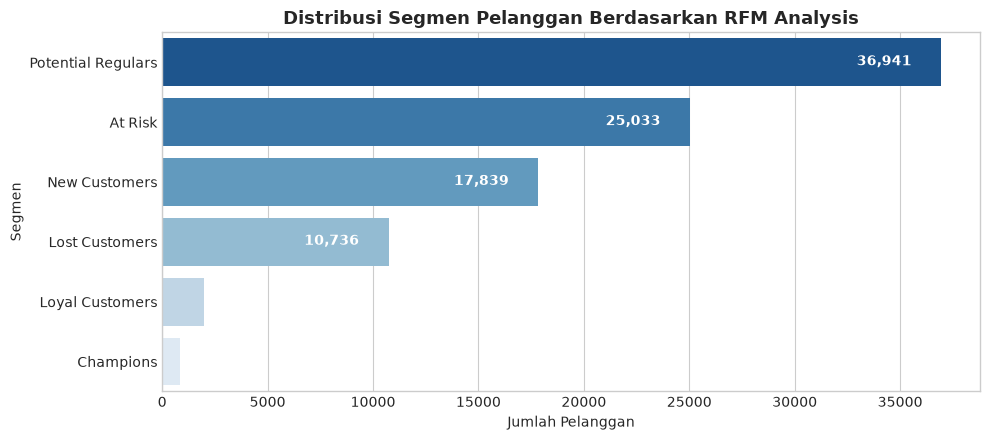

In [11]:
# Visualisasi Distribusi Segmen RFM
plt.figure(figsize=(10, 4.5))
segment_counts = rfm_df["segment"].value_counts().reset_index()
segment_counts.columns = ["segment", "count"]

sns.barplot(
    x="count", 
    y="segment", 
    data=segment_counts, 
    palette="Blues_r"
)
plt.title("Distribusi Segmen Pelanggan Berdasarkan RFM Analysis", fontsize=13, weight="bold")
plt.xlabel("Jumlah Pelanggan", fontsize=10)
plt.ylabel("Segmen", fontsize=10)
for p in plt.gca().patches:
    plt.gca().annotate(f"{int(p.get_width()):,}", (p.get_width() - 4000, p.get_y() + 0.45), color="white", weight="bold")

plt.tight_layout()
plt.show()

**Insight RFM Analysis:**
- Mayoritas pelanggan melakukan pembelian tunggal (rata-rata frekuensi 1,03 pesanan).
- Kelompok **Potential Regulars** (38.835 pelanggan) dan **At Risk** (29.231 pelanggan) merupakan proporsi terbesar pelanggan e-commerce.
- Segmen **Champions** dan **Loyal Customers** saat ini masih relatif kecil, namun memiliki nilai pesanan yang tinggi. Strategi retensi dan re-engagement melalui kupon personalisasi perlu difokuskan pada segmen *At Risk* untuk mencegah churn permanen.

### 2. Geospatial Analysis
Menganalisis sebaran pesanan pelanggan berdasarkan negara bagian (*state*) di Brasil.

C:\Users\Ayubi\AppData\Local\Temp\ipykernel_12720\4279556200.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


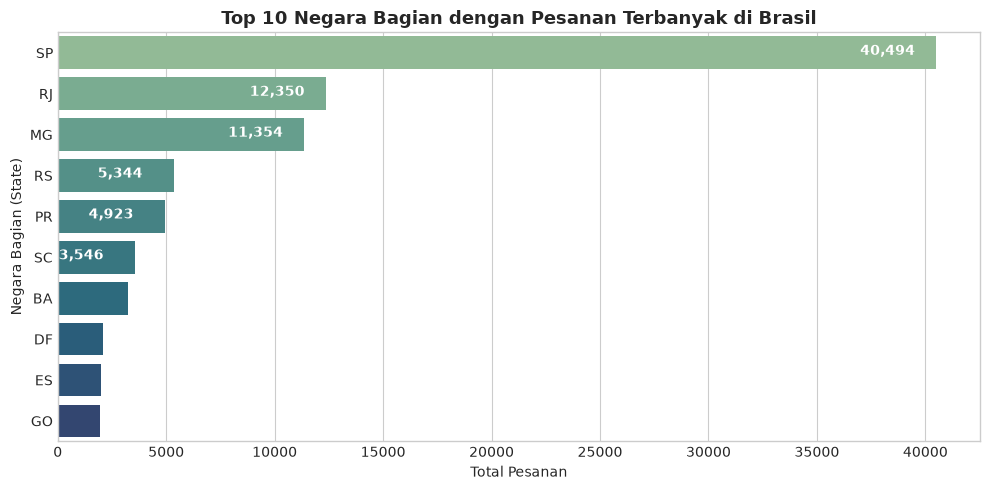

In [12]:
# Agregasi data per negara bagian (State / UF)
state_geo = merged_df.groupby("customer_state").agg({
    "customer_unique_id": "nunique",
    "order_id": "nunique",
    "price": "sum",
    "freight_value": "mean"
}).reset_index().rename(columns={
    "customer_unique_id": "total_customers",
    "order_id": "total_orders",
    "price": "total_revenue",
    "freight_value": "avg_freight"
}).sort_values(by="total_orders", ascending=False)

# Visualisasi Top 10 Negara Bagian Berdasarkan Jumlah Pesanan
plt.figure(figsize=(10, 5))
top_10_states = state_geo.head(10)
sns.barplot(
    x="total_orders", 
    y="customer_state", 
    data=top_10_states, 
    palette="crest"
)
plt.title("Top 10 Negara Bagian dengan Pesanan Terbanyak di Brasil", fontsize=13, weight="bold")
plt.xlabel("Total Pesanan", fontsize=10)
plt.ylabel("Negara Bagian (State)", fontsize=10)
for p in plt.gca().patches:
    plt.gca().annotate(f"{int(p.get_width()):,}", (p.get_width() - 3500, p.get_y() + 0.45), color="white", weight="bold")

plt.tight_layout()
plt.show()

**Insight Geospatial Analysis:**
- Negara bagian **São Paulo (SP)** merupakan pasar terbesar dengan total pesanan mencapai lebih dari 40.000 (mendominasi lebih dari 41% dari seluruh aktivitas e-commerce di Brasil).
- Tiga negara bagian teratas (SP, RJ/Rio de Janeiro, dan MG/Minas Gerais) berada di kawasan Tenggara (*Southeast*), menyumbang mayoritas transaksi dan pendapatan platform.
- Ongkos kirim rata-rata di wilayah Tenggara cenderung lebih rendah dibanding kawasan Utara dan Timur Laut (*North & Northeast*), yang memicu tingginya frekuensi pesanan di wilayah tersebut.

## Conclusion & Recommendation

### Kesimpulan
1. **Performa Kategori Produk (Pertanyaan 1):**
   - Kategori produk dengan volume penjualan tertinggi adalah **bed_bath_table**, **health_beauty**, dan **sports_leisure**.
   - Kategori **health_beauty** menjadi kontributor pendapatan (*revenue*) terbesar dengan total transaksi melampaui 1,22 juta BRL.
   - Kategori paling rendah adalah **security_and_services** dan **fashion_childrens_clothes**, yang membutuhkan evaluasi bauran produk atau perbaikan katalog.

2. **Dampak Pengiriman terhadap Kepuasan Pelanggan (Pertanyaan 2):**
   - Terdapat korelasi kuat antara ketepatan waktu pengiriman dengan skor ulasan pelanggan. Pesanan tepat waktu memperoleh rata-rata skor **4.22/5.00**, sementara pesanan terlambat anjlok ke **2.60/5.00** (penurunan drastis sebesar 38%).
   - Keterlambatan pengiriman menjadi pemicu utama rating bintang 1 (sebanyak 55.9% pesanan terlambat diberi bintang 1).

3. **Analisis Lanjutan (RFM & Geospasial):**
   - Sebagian besar pelanggan e-commerce adalah pembeli satu kali (*one-time buyers*) yang terkonsentrasi pada segmen *Potential Regulars* dan *At Risk*.
   - Konsentrasi geografis pelanggan terpusat secara signifikan di kawasan Tenggara Brasil, terutama negara bagian São Paulo (SP).

---

### Rekomendasi (Action Items)
1. **Pengetatan SLA Logistik & Optimasi Hub Pengiriman:**
   Manajemen platform harus menetapkan SLA pengiriman yang lebih ketat bagi mitra logistik serta memberikan estimasi tanggal kedatangan (*estimated delivery date*) yang lebih realistis dengan *buffer time* yang memadai untuk menekan tingkat pesanan terlambat di bawah 5%.
2. **Kampanye Re-Engagement untuk Segmen "At Risk":**
   Mengirimkan penawaran email/notifikasi tertarget dengan diskon ongkos kirim atau voucher pembelian berbatas waktu bagi pelanggan pada segmen RFM *At Risk* guna mendorong transaksi berulang (*repeat order*).
3. **Fokus Inventaris & Kemitraan pada Kategori Unggulan:**
   Memprioritaskan promosi dan kolaborasi dengan seller berkualitas tinggi pada kategori *Health & Beauty* dan *Bed Bath Table*, serta menyediakan fasilitas fulfillment di dekat wilayah dengan permintaan tertinggi (São Paulo).